# Which Batman stories deserve a second look?

Twenty candidates for a reranking discussion: ten from early episodes, ten from the rest of the list. We look for stories whose **current BatChat rank disagrees with two held-out models**, then examine the actual books and the limits of the comparison.

**Rank 1 is best.** “Move up” means a smaller rank number. These are prompts for rereading, not forecasts of the hosts' decisions: we have one ranking snapshot, not a history of rerankings.

By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

In [1]:
from itertools import pairwise
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import DisjointSet
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlepad": 12,
        "figure.dpi": 120,
        "savefig.dpi": 200,
    },
)
BLUE, ORANGE, GREY = "#2767A0", "#D57927", "#75818C"

stories = pd.read_csv(DATA / "stories.csv").merge(
    pd.read_csv(DATA / "story_features.csv"), on="story_id", validate="one_to_one"
)
issues = pd.read_csv(DATA / "issues.csv")
N = len(stories)
y = stories["rank"].to_numpy(dtype=float)
print(f"{N} ranked stories, from {stories.title[0]} (#1) to {stories.title[N - 1]} (#{N})")

740 ranked stories, from Year One (#1) to Batman: Three Jokers #1-3 (#740)


## First, make the disagreement earn its place

Ridge regression and a random forest use creators, characters, publication year, format, issue count and pre-publication creator awards. The main models **exclude discussion timing**; being early cannot itself earn a place on the shortlist. A third fit adds discussion timing as a sensitivity check.

Stories sharing an issue or an episode stay together in five held-out folds. Every transformation is fitted on the training fold. Neither outside ratings nor the actual rank are inputs. This is the same feature recipe as the prediction notebook, with timing separated out.

In [2]:
ROLES = ["writers", "pencilers", "inkers", "colorists", "letterers", "editors"]
NAMES = ["narrative_" + role for role in ROLES]
CAST = ["featured_entity_ids", "antagonists_entity_ids"]
WHEN = ["cover_year_start", "issue_count"]
AWARDS = ["creator_eisner_personal_wins_pre_publication"]

X = stories[
    ["medium", "format_hint", "cover_year_start", "issue_count", *NAMES, *CAST, *AWARDS]
].copy()
dates = pd.to_datetime(stories.discussion_date)
X["discussion_day"] = (dates - dates.min()).dt.days
X[NAMES + CAST] = X[NAMES + CAST].fillna("")


def model(numbers, name_lists, forest=False):
    """Fit numeric, format and name transformations within each training fold."""
    features = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(numbers)),
        (OneHotEncoder(handle_unknown="ignore", min_frequency=3), ["medium", "format_hint"]),
        *[
            (CountVectorizer(token_pattern=r"[^|]+", lowercase=False, binary=True, min_df=3), col)
            for col in name_lists
        ],
    )
    if forest:
        return make_pipeline(
            features,
            RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
        )
    return make_pipeline(features, RidgeCV(alphas=np.logspace(-1, 3, 9)))


# Stories that share an issue or an episode stay in the same fold.
links = pd.concat(
    [
        pd.DataFrame({"story_id": stories.story_id, "key": "episode " + stories.episode_url}),
        pd.DataFrame(
            {"story_id": issues.story_id, "key": "issue " + issues.issue_id.astype("string")}
        ),
    ]
).dropna()
linked = DisjointSet(stories.story_id)
for _, ids in links.groupby("key").story_id:
    for a, b in pairwise(ids):
        linked.merge(a, b)
label = {story: min(group) for group in linked.subsets() for story in group}
groups = stories.story_id.map(label).to_numpy()
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, groups=groups))

models = {
    "Ridge": model(WHEN + AWARDS, NAMES + CAST),
    "Forest": model(WHEN + AWARDS, NAMES + CAST, forest=True),
    "Ridge + discussion timing": model(WHEN + AWARDS + ["discussion_day"], NAMES + CAST),
    "Training-fold average": DummyRegressor(),
}
predictions = {name: cross_val_predict(m, X, y, cv=folds) for name, m in models.items()}
validation = pd.DataFrame(
    {
        "Mean absolute error": {name: mean_absolute_error(y, p) for name, p in predictions.items()},
        "Rank-order correlation": {
            name: pd.Series(y).corr(pd.Series(p), method="spearman")
            for name, p in predictions.items()
        },
    }
)
display(
    validation.style.format({"Mean absolute error": "{:.0f}", "Rank-order correlation": "{:.2f}"})
)

,Mean absolute error,Rank-order correlation
Ridge,172,0.33
Forest,168,0.35
Ridge + discussion timing,171,0.34
Training-fold average,185,-0.09


## Raw score versus a place on the list

Regressors pull extreme predictions toward the middle. A predicted rank of 300 does not mean “replace #1 with #300.” We also sort all held-out predictions into **model positions** on the 740-story list. That makes the comparison about relative order; it does not make the predictions more accurate.

A candidate must have the same suggested direction in both models, using **both raw predictions and model positions**. We prioritize the smaller of the two position gaps. A separate column records whether adding discussion timing reverses the direction. These are model disagreements, not confidence intervals.

In [3]:
comparison = stories.copy()
for name in ["Ridge", "Forest", "Ridge + discussion timing"]:
    comparison[name] = predictions[name]
    comparison[name + " position"] = comparison[name].rank(method="average")
comparison["ridge_gap"] = comparison["rank"] - comparison["Ridge position"]
comparison["forest_gap"] = comparison["rank"] - comparison["Forest position"]
comparison["move"] = np.where(comparison.ridge_gap > 0, "Move up", "Move down")
comparison["agreement"] = (
    np.sign(comparison.ridge_gap).eq(np.sign(comparison.forest_gap))
    & np.sign(comparison.ridge_gap).eq(np.sign(comparison["rank"] - comparison.Ridge))
    & np.sign(comparison.ridge_gap).eq(np.sign(comparison["rank"] - comparison.Forest))
    & comparison.ridge_gap.ne(0)
)
comparison["shared_gap"] = np.minimum(comparison.ridge_gap.abs(), comparison.forest_gap.abs())
comparison["timing_stable"] = np.sign(comparison.ridge_gap).eq(
    np.sign(comparison["rank"] - comparison["Ridge + discussion timing position"])
)
episodes = stories[["episode_url", "discussion_date"]].dropna().drop_duplicates("episode_url")
episodes = episodes.sort_values(["discussion_date", "episode_url"])
early_urls = set(episodes.head(int(np.ceil(len(episodes) / 4))).episode_url)
comparison["early"] = comparison.episode_url.isin(early_urls)
print(
    f"Early = first quarter of dated episodes represented here ({len(early_urls)} of {len(episodes)})."
)
print(f"{comparison.agreement.sum()} of {N} stories meet the direction-agreement rule.")

Early = first quarter of dated episodes represented here (63 of 252).
462 of 740 stories meet the direction-agreement rule.


## The shortlist: early episodes first

Five upward and five downward candidates from the first quarter of dated episodes; the same from the remaining episodes. Within each group, select the largest shared position gaps. This balances the reading list rather than estimating how often early stories deserve a move.

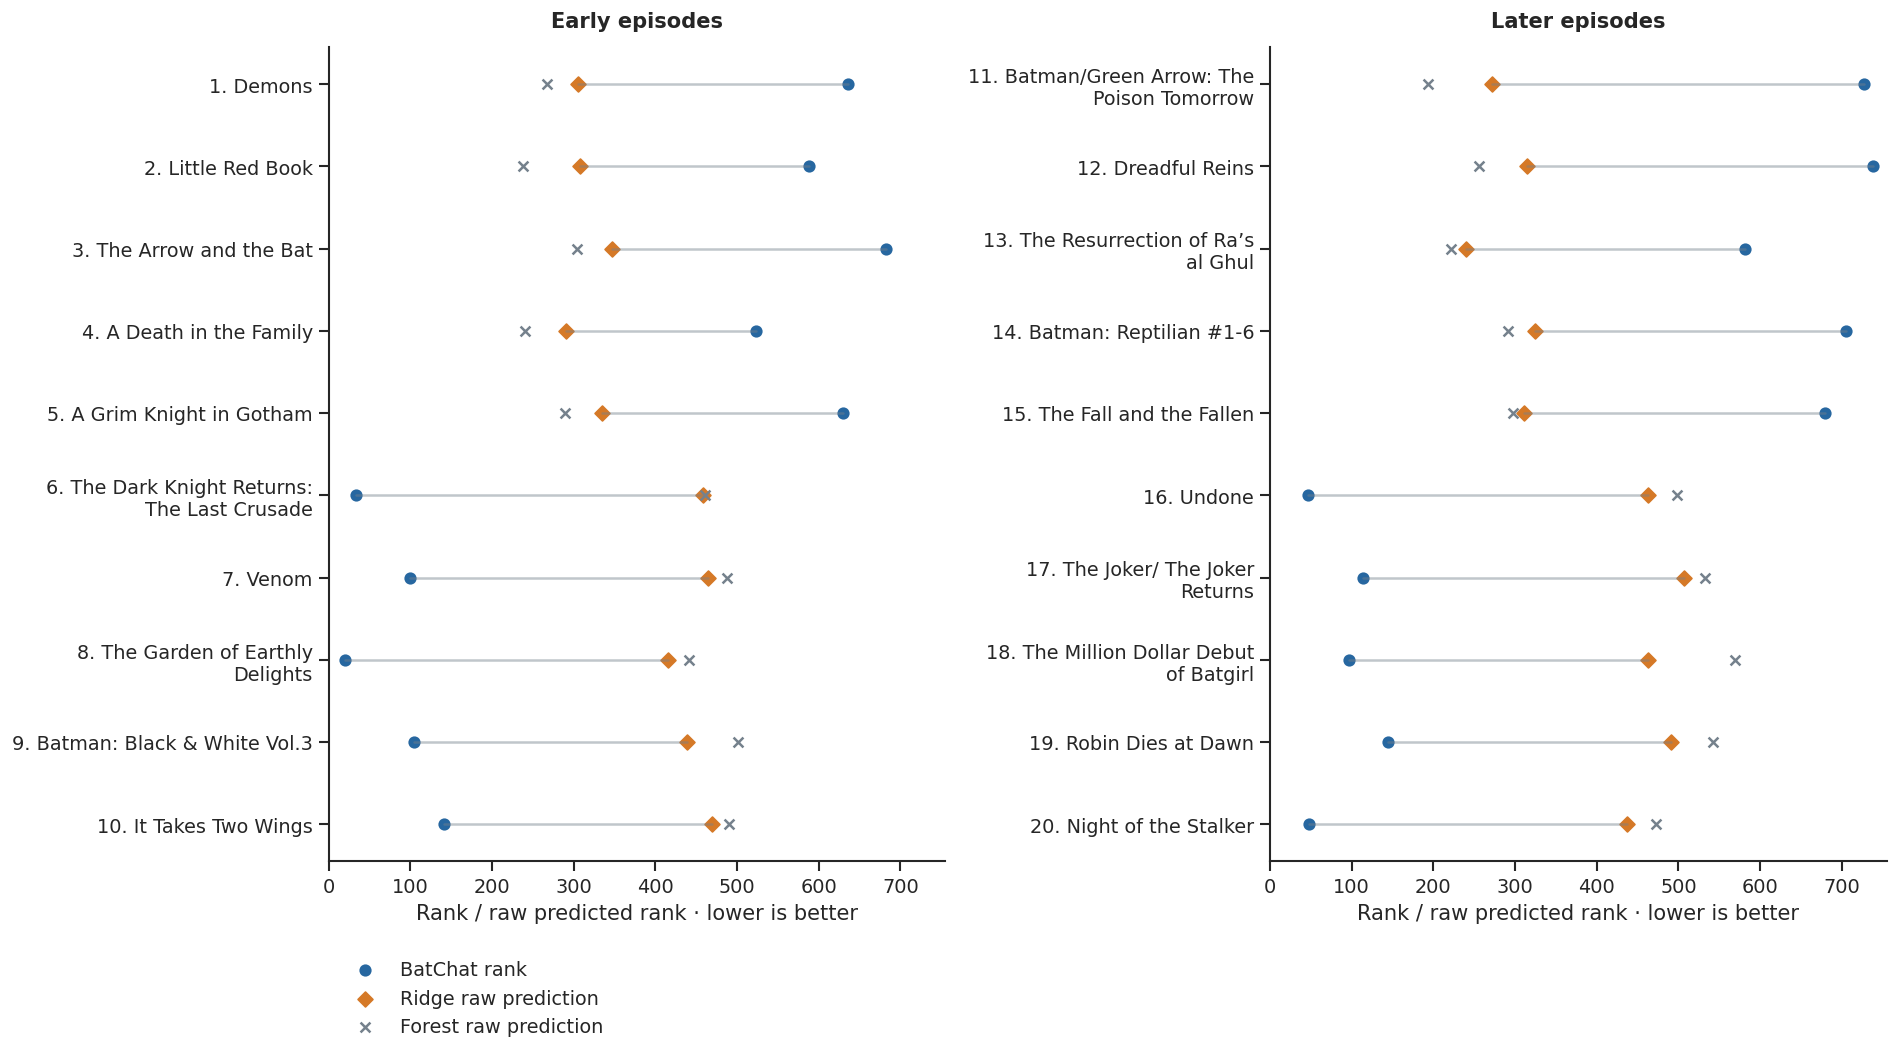

,Story,Actual,Ridge position,Forest position,Same direction with timing?
Case,,,,,
1,Demons,636,102,77,True
2,Little Red Book,588,111,38,True
3,The Arrow and the Bat,683,233,155,True
4,A Death in the Family,523,77,44,True
5,A Grim Knight in Gotham,630,187,118,True
6,The Dark Knight Returns: The Last Crusade,33,662,590,True
7,Venom,100,671,640,True
8,The Garden of Earthly Delights,20,555,553,True
9,Batman: Black & White Vol.3,104,628,662,True


In [4]:
candidates = comparison[comparison.agreement & comparison.discussion_date.notna()].copy()
shortlist = pd.concat(
    [
        candidates[candidates.early.eq(early) & candidates.move.eq(move)]
        .sort_values(["shared_gap", "rank"], ascending=[False, True])
        .head(5)
        for early in [True, False]
        for move in ["Move up", "Move down"]
    ]
).copy()
assert len(shortlist) == 20 and shortlist.story_id.is_unique
assert set(shortlist.story_id).issubset(stories.story_id)
shortlist["case"] = range(1, len(shortlist) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharex=True)
for ax, early in zip(axes, [True, False]):
    panel = shortlist[shortlist.early.eq(early)]
    for pos, row in enumerate(panel.itertuples()):
        ax.plot([row.rank, row.Ridge], [pos, pos], color=GREY, alpha=0.45, linewidth=1.5)
        ax.scatter(row.rank, pos, color=BLUE, s=40, label="BatChat rank" if pos == 0 else None)
        ax.scatter(
            row.Ridge,
            pos,
            color=ORANGE,
            s=40,
            marker="D",
            label="Ridge raw prediction" if pos == 0 else None,
        )
        ax.scatter(
            row.Forest,
            pos,
            color=GREY,
            s=35,
            marker="x",
            label="Forest raw prediction" if pos == 0 else None,
        )
    ax.set(
        yticks=range(len(panel)),
        yticklabels=[fill(f"{r.case}. {r.title}", 30) for r in panel.itertuples()],
        xlabel="Rank / raw predicted rank · lower is better",
        xlim=(0, N + 15),
        title="Early episodes" if early else "Later episodes",
    )
    ax.invert_yaxis()
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.1))
fig.tight_layout()
plt.show()

summary_columns = {
    "case": "Case",
    "title": "Story",
    "rank": "Actual",
    "Ridge position": "Ridge position",
    "Forest position": "Forest position",
    "timing_stable": "Same direction with timing?",
}
display(
    shortlist[list(summary_columns)]
    .rename(columns=summary_columns)
    .set_index("Case")
    .style.format({k: "{:.0f}" for k in ["Ridge position", "Forest position"]})
)

## Twenty case studies

Each case separates what the models suggest from what the data can support. Episode links let readers return to the original discussion. Publication-year and creator comparisons describe this ranked sample, not all Batman comics.

In [5]:
case_notes = {
    "Demons": "An animated-continuity annual with Bruce Timm, Glen Murakami and Paul Dini is a natural contrast with *Mad Love* (#34) and the *Holiday Special* (#39). Its Ra’s al Ghul/Etrigan occult plot gives a specific rereading question: does this adventure deserve such a different place from those celebrated animated books? The credits are complete; the model cannot judge the execution of that premise.",
    "Little Red Book": "Kelley Puckett and Mike Parobeck’s Rupert Thorne ledger chase sits far below other Puckett stories such as *Badge of Honor* (#102) and *Super Friends* (#172). This is a comparatively clean within-creator comparison with complete attribution. Revisit the pacing and payoff rather than assuming shared creators imply shared quality.",
    "The Arrow and the Bat": "Compare this Dennis O’Neil Batman/Green Arrow arc with *It Takes Two Wings* (#141), another early-discussed team-up that the models miss in the opposite direction. Similar heroes are clearly not enough to explain the hosts’ preference. Its complete credits make a reread more informative than a metadata repair.",
    "A Death in the Family": "The Jim Starlin/Jim Aparo story sits well below Starlin’s *The Cult* (#29). Jason Todd’s conflict with Bruce and the Joker storyline are present in the synopsis, but cultural importance is not a model feature. The matched Goodreads edition provides a separate audience comparison below; it cannot tell us which rank the hosts should prefer.",
    "A Grim Knight in Gotham": "James Tynion IV, Scott Snyder and Eduardo Risso give the model recognizable credits, while the actual rank stays low. Contrast it with Tynion’s *Rise of the Batmen* (#49), without treating that shared writer as a quality guarantee. No usable plot summary is available here, so the data cannot explain the story-level disagreement.",
    "The Dark Knight Returns: The Last Crusade": "Brian Azzarello, Frank Miller and John Romita Jr.’s story is much better liked than its metadata suggests. This is a useful counterexample to treating creators or franchise labels as verdicts. The available synopsis is only a short opening: return to the episode before attributing the gap to any particular scene or theme.",
    "Venom": "The addiction-and-recovery premise is visible in the summaries but absent from the main feature model. Compare this highly placed O’Neil arc with his much lower *The Arrow and the Bat* (#683), rather than reading the model’s downward suggestion as a correction. Matched outside ratings offer context, not a direct conversion to a BatChat rank.",
    "The Garden of Earthly Delights": "Swamp Thing’s confrontation with Gotham makes this an unusual Batman reading, with Alan Moore, John Totleben and Rick Veitch credited. Moore has only three attributed stories in this snapshot; the five-fold training sets cannot reliably learn a Moore-specific effect at a three-story minimum. The gap may reveal sparse representation as much as an exceptional book.",
    "Batman: Black & White Vol.3": "**Repair the metadata before proposing a move.** This collection has no resolved selected-story credits or publication year and an incomplete issue list. Both models are filling gaps rather than assessing a well-described book. It earns a case study because a very large, apparently agreed-upon residual can still be a bad reranking candidate.",
    "It Takes Two Wings": "Doug Moench and Gene Colan’s Batman/Green Arrow/Black Canary story ranks well above the models’ estimates. The synopsis centers on a dispute over stolen evidence and corporate wrongdoing. Compare the hosts’ response with *The Arrow and the Bat*: the shared cast points to a reading pair, not an interchangeable set of stories.",
    "Batman/Green Arrow: The Poison Tomorrow": "The sharpest later upward candidate is another Dennis O’Neil Batman/Green Arrow book, but it is near the bottom of the actual list. This puts a third point beside *The Arrow and the Bat* and *It Takes Two Wings*. The credits are resolved, but no usable synopsis is available; the episode is the evidence for why this team-up failed for the hosts.",
    "Dreadful Reins": "Tom King and Mitch Gerads’ Riddler story is almost last, despite the model’s favorable estimate. Compare the response with King stories such as *Cold Days* (#3) and *Some Of These Days* (#7). *The Fall and the Fallen*, also selected here, was discussed in the same episode: their held-out predictions are appropriately grouped, not independent confirmations.",
    "The Resurrection of Ra’s al Ghul": "**A crossover needs an attribution check first.** The reading list is incomplete and only about 91% of listed references have resolved narrative attribution. Several prominent writers and artists can make the feature list look strong while saying little about the event’s coherence. The issue-level outside rating has unresolved scope, so it is excluded from the audience comparison.",
    "Batman: Reptilian #1-6": "Garth Ennis and Liam Sharp’s series is far below both predictions. Ennis has no other selected-story writing credit in this snapshot, so the minimum-frequency rule removes any reliable Ennis-specific signal; this is not the model endorsing his writing. A matched, sufficiently populated issue-rating comparison can help frame the disagreement, but the missing synopsis leaves the story explanation open.",
    "The Fall and the Fallen": "This Tom King arc invites comparison with *Cold Days* (#3), but one sixth of its listed references lacks resolved narrative attribution. Its shared episode with *Dreadful Reins* also means these two residuals should not be counted as separate evidence of a general King effect. Check the selected material before making a case to move it upward.",
    "Undone": "The summary follows Bruce and Alfred after Damian’s death; creator names and dates miss how grief is conveyed on the page. Peter Tomasi’s *Born to Kill* (#221) is a useful same-writer contrast. The strong matched outside rating below is a reason to question the model’s downward suggestion, making this a model blind spot worth keeping on the reading list.",
    "The Joker/ The Joker Returns": "The two Joker stories from *Batman* #1 outperform the model’s view of their era and credits. The selected narratives, rather than every story in that issue, are what the hosts ranked. Whole-issue reader scores are therefore not a like-for-like check. Historical or narrative significance is a possible missing dimension, not something this residual proves.",
    "The Million Dollar Debut of Batgirl": "Barbara Gordon’s costumed intervention against Killer Moth is visible in the synopsis; a character-presence flag does not encode a debut’s importance. Other Gardner Fox stories in the sample sit much lower, such as *Remarkable Ruse of the Riddler* (#346). The issue rating includes other material, so it is intentionally not used as corroboration.",
    "Robin Dies at Dawn": "The isolation experiment, hallucinated death of Robin and Batman’s loss of confidence make this more specific than a typical 1963 Batman story. Compare it with *The Joker/The Joker Returns*, another Bill Finger outlier in the same direction. The metadata cannot decide whether the hosts rewarded its premise, its execution or its place in Batman history.",
    "Night of the Stalker": "Batman witnesses a child’s parents being killed and pursues the gunmen: the synopsis makes the echo of his origin explicit. Sal Amendola’s sparse representation limits what the model can learn about this team. This is another plausible exception to broad era-and-credit patterns; whole-issue ratings are excluded because the ranked story is only part of the issue.",
}
texts = pd.read_csv(DATA / "story_texts.csv")
for row in shortlist.itertuples():
    audience = []
    if row.goodreads_match_scope == "same_story" and row.goodreads_rating_count >= 100:
        audience.append(
            f"Goodreads {row.goodreads_rating:.2f}/5 ({int(row.goodreads_rating_count):,} ratings)"
        )
    if row.roundup_narrative_scope == "all_indexed_narratives":
        for label, prefix, minimum in [
            ("RoundUp readers", "user", 5),
            ("RoundUp critics", "critic", 3),
        ]:
            if (
                getattr(row, f"roundup_{prefix}_complete")
                and getattr(row, f"roundup_{prefix}_min_count") >= minimum
            ):
                audience.append(f"{label} {getattr(row, f'roundup_{prefix}_rating'):.2f}/10")
    sources = (
        texts.loc[texts.story_id.eq(row.story_id) & texts.text_status.eq("available"), "source_url"]
        .dropna()
        .unique()
    )
    source_link = f" · [Plot-summary source]({sources[0]})" if len(sources) else ""
    note = case_notes.get(
        row.title,
        "New candidate: inspect the episode and matched metadata before interpreting the gap.",
    )
    display(
        Markdown(
            f"### {row.case}. {row.title} — {row.move.lower()}?\n\n"
            f"**Actual #{row.rank}; ridge {row.Ridge:.0f}, forest {row.Forest:.0f}.** "
            f"{'Early' if row.early else 'Later'} discussion, {str(row.discussion_date)[:4]}.\n\n"
            + note
            + "\n\n"
            + ("Matched audience check: " + "; ".join(audience) + ".\n\n" if audience else "")
            + f"[Original discussion]({row.episode_url})"
            + source_link
        )
    )

### 1. Demons — move up?

**Actual #636; ridge 306, forest 267.** Early discussion, 2021.

An animated-continuity annual with Bruce Timm, Glen Murakami and Paul Dini is a natural contrast with *Mad Love* (#34) and the *Holiday Special* (#39). Its Ra’s al Ghul/Etrigan occult plot gives a specific rereading question: does this adventure deserve such a different place from those celebrated animated books? The credits are complete; the model cannot judge the execution of that premise.

[Original discussion](https://comicsxf.com/2021/10/21/batchat-with-matt-will-ep-5-batman-is-for-the-children-w-dan-grote/) · [Plot-summary source](https://dc.fandom.com/wiki/Batman_Adventures_Annual_Vol_1_2)

### 2. Little Red Book — move up?

**Actual #588; ridge 308, forest 238.** Early discussion, 2022.

Kelley Puckett and Mike Parobeck’s Rupert Thorne ledger chase sits far below other Puckett stories such as *Badge of Honor* (#102) and *Super Friends* (#172). This is a comparatively clean within-creator comparison with complete attribution. Revisit the pacing and payoff rather than assuming shared creators imply shared quality.

[Original discussion](https://comicsxf.com/2022/06/16/batchat-with-matt-will-episode-39-the-never-ending-war-game-w-josh-weil/) · [Plot-summary source](https://dc.fandom.com/wiki/Batman_Adventures_Vol_1_9)

### 3. The Arrow and the Bat — move up?

**Actual #683; ridge 347, forest 304.** Early discussion, 2022.

Compare this Dennis O’Neil Batman/Green Arrow arc with *It Takes Two Wings* (#141), another early-discussed team-up that the models miss in the opposite direction. Similar heroes are clearly not enough to explain the hosts’ preference. Its complete credits make a reread more informative than a metadata repair.

[Original discussion](https://comicsxf.com/2022/09/08/batchat-with-matt-will-episode-51-a-hickman-chart-on-monkey-rankings-w-josh-weil/) · [Plot-summary source](https://dc.fandom.com/wiki/Batman:_Legends_of_the_Dark_Knight_Vol_1_127)

### 4. A Death in the Family — move up?

**Actual #523; ridge 290, forest 240.** Early discussion, 2022.

The Jim Starlin/Jim Aparo story sits well below Starlin’s *The Cult* (#29). Jason Todd’s conflict with Bruce and the Joker storyline are present in the synopsis, but cultural importance is not a model feature. The matched Goodreads edition provides a separate audience comparison below; it cannot tell us which rank the hosts should prefer.

Matched audience check: Goodreads 4.08/5 (40,403 ratings); RoundUp readers 7.10/10.

[Original discussion](https://comicsxf.com/2022/05/19/batchat-with-matt-will-episode-35-two-deaths-and-one-good-day-for-jason-todd/) · [Plot-summary source](https://dc.fandom.com/wiki/Batman_Vol_1_426)

### 5. A Grim Knight in Gotham — move up?

**Actual #630; ridge 335, forest 289.** Early discussion, 2021.

James Tynion IV, Scott Snyder and Eduardo Risso give the model recognizable credits, while the actual rank stays low. Contrast it with Tynion’s *Rise of the Batmen* (#49), without treating that shared writer as a quality guarantee. No usable plot summary is available here, so the data cannot explain the story-level disagreement.

[Original discussion](https://comicsxf.com/2021/12/30/batchat-with-matt-will-episode-15-new-batman-new-year/)

...

### 16. Undone — move down?

**Actual #47; ridge 463, forest 499.** Later discussion, 2024.

The summary follows Bruce and Alfred after Damian’s death; creator names and dates miss how grief is conveyed on the page. Peter Tomasi’s *Born to Kill* (#221) is a useful same-writer contrast. The strong matched outside rating below is a reason to question the model’s downward suggestion, making this a model blind spot worth keeping on the reading list.

Matched audience check: RoundUp readers 9.60/10; RoundUp critics 9.40/10.

[Original discussion](https://comicsxf.com/2024/06/20/batchat-with-matt-will-if-he-can-fight-like-a-man-he-can-write-like-a-man-w-josh-weil/) · [Plot-summary source](https://dc.fandom.com/wiki/Batman_and_Robin_Vol_2_18)

### 17. The Joker/ The Joker Returns — move down?

**Actual #114; ridge 507, forest 533.** Later discussion, 2023.

The two Joker stories from *Batman* #1 outperform the model’s view of their era and credits. The selected narratives, rather than every story in that issue, are what the hosts ranked. Whole-issue reader scores are therefore not a like-for-like check. Historical or narrative significance is a possible missing dimension, not something this residual proves.

[Original discussion](https://comicsxf.com/2023/01/26/batchat-with-matt-will-the-jokers-first-laughs/) · [Plot-summary source](https://dc.fandom.com/wiki/Batman_Vol_1_1)

### 18. The Million Dollar Debut of Batgirl — move down?

**Actual #97; ridge 463, forest 569.** Later discussion, 2023.

Barbara Gordon’s costumed intervention against Killer Moth is visible in the synopsis; a character-presence flag does not encode a debut’s importance. Other Gardner Fox stories in the sample sit much lower, such as *Remarkable Ruse of the Riddler* (#346). The issue rating includes other material, so it is intentionally not used as corroboration.

[Original discussion](https://comicsxf.com/2023/04/20/batchat-with-matt-will-from-batgirl-to-oracle/) · [Plot-summary source](https://dc.fandom.com/wiki/Detective_Comics_Vol_1_359)

### 19. Robin Dies at Dawn — move down?

**Actual #145; ridge 491, forest 542.** Later discussion, 2023.

The isolation experiment, hallucinated death of Robin and Batman’s loss of confidence make this more specific than a typical 1963 Batman story. Compare it with *The Joker/The Joker Returns*, another Bill Finger outlier in the same direction. The metadata cannot decide whether the hosts rewarded its premise, its execution or its place in Batman history.

[Original discussion](https://comicsxf.com/2023/09/14/batchat-with-matt-will-batchat-r-i-p/) · [Plot-summary source](https://dc.fandom.com/wiki/Batman_Vol_1_156)

### 20. Night of the Stalker — move down?

**Actual #48; ridge 437, forest 473.** Later discussion, 2025.

Batman witnesses a child’s parents being killed and pursues the gunmen: the synopsis makes the echo of his origin explicit. Sal Amendola’s sparse representation limits what the model can learn about this team. This is another plausible exception to broad era-and-credit patterns; whole-issue ratings are excluded because the ranked story is only part of the issue.

[Original discussion](https://comicsxf.com/2025/01/23/batchat-with-matt-will-farewell-darwyn-cooke/) · [Plot-summary source](https://dc.fandom.com/wiki/Detective_Comics_Vol_1_439)

## What would make this a real reranking forecast?

A second snapshot with explicit rerankings would let us test whether these disagreements precede an actual move. Until then, an unusually high or low rank can be a deliberate preference that metadata misses. Early selection gives older discussions attention; it is not evidence that they are less valid.

The strongest rereading prompt is agreement across models plus a concrete comparison with related stories. A timing-sensitive result or disagreement with outside readers makes a case more debatable, not more certain.